For braking, the total stopping distance is given by the equation $d=v_0t_r + \frac{v_0^2}{2μg}$, where $t_r$ is the reaction time of the driver and the braking produces a constant deceleration of $a=-μg$ which gives the stopping distance to be $\frac{v^2}{2μg}$. For model simulation and verification, we use example parameters. (All parameters used are taken in SI units.)

Theoretical braking time: 2.91247997670016
Theoretical braking distance: 29.1247997670016
Expected total stopping distance: 43.124799767001605

Braking distance calculated by Euler: 29.224735734003243
Braking distance calculated by RK4: 29.12479976700165

Total stopping distance calculated using Euler: 43.22473573400325
Total stopping distance calculated using RK4: 43.12479976700165


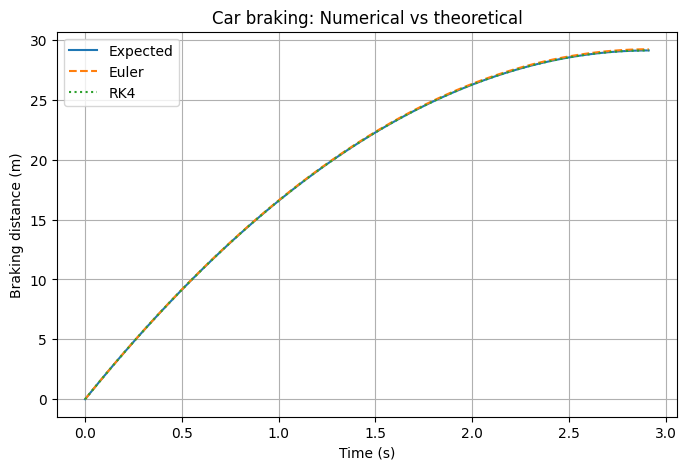

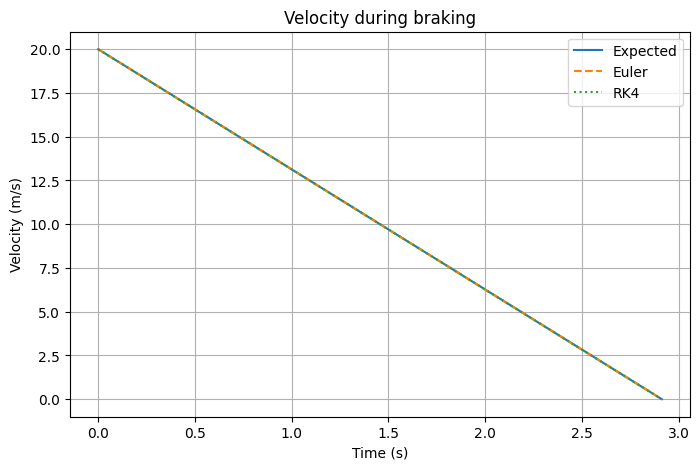

In [49]:

import numpy as np
import matplotlib.pyplot as plt

# The example parameters
m = 1200
mu = 0.7
g = 9.81
t_r = 0.7
v_0 = 20.0
dt = 0.01
a = mu * g

t_s = v_0 / a
d_brake_theoretical = v_0**2 / (2 * a)
d_total_theoretical = v_0 * t_r + d_brake_theoretical

print("Theoretical braking time:", t_s)
print("Theoretical braking distance:", d_brake_theoretical)
print("Expected total stopping distance:", d_total_theoretical)

def f(y):
    x, v = y
    return np.array([v, -a]) # This function directly gives the rate of change of the variable y, i.e., rate of change of position and velocity.


def euler(dt):
    x = 0.0
    v = v_0
    t = 0.0
    time = [t]
    position = [x]
    velocity = [v]
    while v > 1e-12: # v>0 will cause rounding off errors so we choose a very small value of v. It is similar to how we chose t > 1e-12.
        h = min(dt, v / a) # We want the minimum of these because we don't want the simulation to continue even after the car stops.
        x = x + v * h
        v = max(0.0, v - a * h) # Same thing. We don't want speed to be negative and continue even after stopping.
        t += h
        time.append(t)
        position.append(x)
        velocity.append(v)
    return np.array(time), np.array(position), np.array(velocity)

def rk4_step(y, h):
    k1 = f(y)
    k2 = f(y + h * k1 / 2)
    k3 = f(y + h * k2 / 2)
    k4 = f(y + h * k3)
    return y + (h / 6) * (k1 + 2*k2 + 2*k3 + k4)


def rk4(dt):
    y = np.array([0.0, v_0])
    t = 0.0
    time = [t]
    position = [y[0]]
    velocity = [y[1]]
    while y[1] > 1e-12:
        h = min(dt, y[1] / a)
        y = rk4_step(y, h)
        y[1] = max(0.0, y[1])
        t += h
        time.append(t)
        position.append(y[0])
        velocity.append(y[1])
    return np.array(time), np.array(position), np.array(velocity)

t_e, x_e, v_e = euler(dt)
t_rk4, x_rk4, v_rk4 = rk4(dt)

print("\nBraking distance calculated by Euler:", x_e[-1])
print("Braking distance calculated by RK4:", x_rk4[-1])

print("\nTotal stopping distance calculated using Euler:", x_e[-1] + v_0 * t_r)
print("Total stopping distance calculated using RK4:", x_rk4[-1] + v_0 * t_r)

t_exact = np.linspace(0, t_s, 200)

# Position vs time graph
x_exact = v_0*t_exact - 0.5*a*t_exact**2
plt.figure(figsize=(8, 5))
plt.plot(t_exact, x_exact, label="Expected")
plt.plot(t_e, x_e, "--", markersize=3, label="Euler")
plt.plot(t_rk4, x_rk4, ":", label="RK4")
plt.xlabel("Time (s)")
plt.ylabel("Braking distance (m)")
plt.title("Car braking: Numerical vs theoretical")
plt.legend()
plt.grid()
plt.show()


# Velocity vs time graph
v_exact = v_0 - a*t_exact
plt.figure(figsize=(8, 5))
plt.plot(t_exact, v_exact, label="Expected")
plt.plot(t_e, v_e, "--", markersize=3, label="Euler")
plt.plot(t_rk4, v_rk4, ":", label="RK4")
plt.xlabel("Time (s)")
plt.ylabel("Velocity (m/s)")
plt.title("Velocity during braking")
plt.legend()
plt.grid()
plt.show()


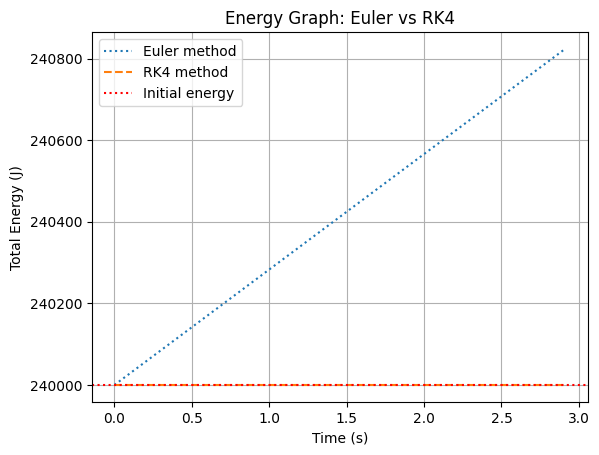

In [50]:
# Calculate energy for Euler method
KE_e = 0.5 * m * v_e**2
W_e = mu * m * g * x_e
E_e = KE_e + W_e

# Calculate energy for RK4 method
KE_rk4 = 0.5 * m * v_rk4**2
W_rk4 = mu * m * g * x_rk4
E_rk4 = KE_rk4 + W_rk4

plt.plot(t_e, E_e, linestyle=':', label='Euler method')

plt.plot(t_rk4, E_rk4, linestyle='--', label='RK4 method')

plt.axhline(0.5 * m * v_0**2, color='red', linestyle=':', label='Initial energy')

plt.xlabel('Time (s)')
plt.ylabel('Total Energy (J)')
plt.title('Energy Graph: Euler vs RK4')
plt.legend()
plt.grid()
plt.show()

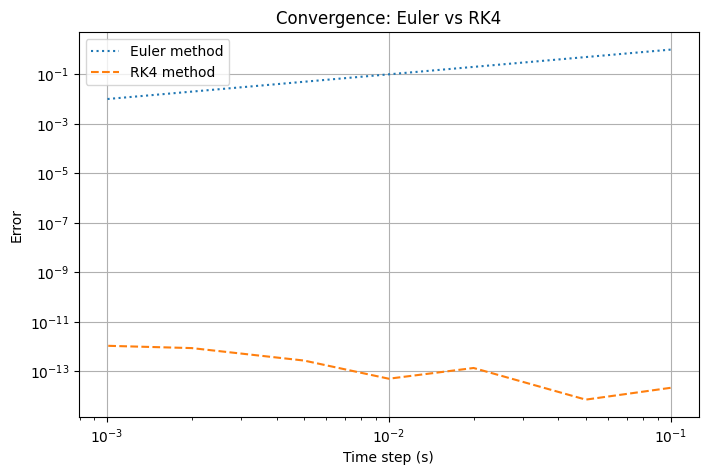

In [53]:
dt = np.array([0.1, 0.05, 0.02, 0.01, 0.005, 0.002, 0.001])
err_e = []
err_rk4 = []
for i in dt:
  t_e, x_e, v_e = euler(i)
  t_rk4, x_rk4, v_rk4 = rk4(i)
  err_e.append(abs(d_brake_theoretical - x_e[-1]))
  err_rk4.append(abs(d_brake_theoretical - x_rk4[-1]))
plt.figure(figsize=(8, 5))
plt.loglog(dt, err_e, linestyle=':',label='Euler method')
plt.loglog(dt, err_rk4, linestyle='--', label='RK4 method')
plt.xlabel('Time step (s)')
plt.ylabel('Error')
plt.title('Convergence: Euler vs RK4')
plt.legend()
plt.grid()
plt.show()